In [ ]:
from datetime import datetime
from IPython.display import display, Markdown
from zoneinfo import ZoneInfo

current_date = datetime.now(ZoneInfo('America/Mexico_City')).strftime("%Y-%m-%d %H:%M:%S")
formatted_text = f"""
# <font color='orange'> Fourier Analysis
<font color='green'> Made by: J. Daniel Arzate | Date: 2020 - Enero 19 </font>

<font color='red'> Las view: {current_date}</font>
"""
display(Markdown(formatted_text))


# <font color='orange'> Fourier Analysis
<font color='green'> Made by: J. Daniel Arzate | Date: 2020 - Enero 19 </font>

<font color='red'> Las view: 2026-10-19 15:31:34</font>


# Teoría

## Análisis en el dominio de la frecuencia: la transformada de Fourier y el PSD

El análisis en el dominio de la frecuencia, también conocido como *análisis espectral*, estudia el contenido de frecuencia de los datos, es decir, estudia la importancia relativa de la variabilidad de la señal a diferentes escalas de tiempo. Esto se hace aplicando primero la transformación de Fourier a los datos, pasando la serie del espacio del tiempo al espacio de la frecuencia.

La herramienta principal es el **PSD** (o Power Spectral Density), también conocido como *espectro de potencia* (o *power spectrum*). Se define como:

$$ PSD \equiv \left| \mathscr{F}[ h(t) ] \right|^2 $$

donde $\mathscr{F}[h(t)]$ es la *transformada de Fourier* de la serie de tiempo $h(t)$:

$$ \mathscr{F}[h(t)] \equiv H(f) \equiv \int_{-\infty}^{\infty} h(t) e^{-i  2\pi ft} dt$$

En principio, la transformada de Fourier ([FT](https://es.wikipedia.org/wiki/Densidad_espectral)) nos da principalmente información sobre dos cosas:

* Las **periodicidades**, visibles en forma de picos delgados a frecuencias determinadas
* Las **auto-correlaciones en las fluctuaciones** de la serie

* Existe una relación directa entre la función de Autocorrelación y el Espectro de Potencias (Power Spectral Density - PSD) a través del teorema [**Wiener–Khinchin theorem**](https://mathworld.wolfram.com/Wiener-KhinchinTheorem.html)

$$ S_{xx}(f) = \mathscr{F}(r_{xx}(\tau)) =  \int_{-\infty }^{\infty } r_{xx}(\tau) e^{-i 2 \pi f \tau} d\tau$$

* Ejemplo Aplicado (Python): http://pdebuyl.be/blog/2017/wiener-khinchin.html


# Estándares de Código y Linter (`ruff`)

En proyectos de sistemas complejos es fundamental mantener un código limpio y legible ([PEP 8](https://peps.python.org/pep-0008/)). Utilizaremos **Ruff**, un linter de alta velocidad.

Ejecuta la siguiente celda para instalar y probar `ruff` directamente en Colab:

* Herramienta didáctica: linter para ver violaciones de código: flake8 o ruff (este último es rapidísimo y está de moda). En Colab: !pip install ruff y luego !ruff check mi_archivo.py


In [20]:
#@title ruff - install
!pip install ruff

In [21]:
%%writefile lint_test.py
import numpy as np
import pandas as pd                          # F401: importado pero nunca usado

frecuencia=2                                 # E225: falta espacio alrededor de =
t = np.arange(0, 1, 1/32)
signal = np.sin( 2*np.pi*frecuencia*t )      # E201/E202: espacios dentro de paréntesis
variable_muerta = 42                         # F841: asignada pero nunca usada

if signal[0] == True:                        # E712: no compares con True
    print("nunca entra")

Overwriting lint_test.py


In [22]:
!ruff check lint_test.py
# !ruff check /content/*.ipynb # Verificar Notebooks

I001 [*] Import block is un-sorted or un-formatted
 --> lint_test.py:1:1
  |
1 | / import numpy as np
2 | | import pandas as pd                          # F401: importado pero nunca usado
  | |___________________^
3 |
4 |   frecuencia=2                                 # E225: falta espacio alrededor de =
  |
help: Organize imports
  |
1 | import numpy as np
  - import pandas as pd                          # F401: importado pero nunca usado
2 + import pandas as pd  # F401: importado pero nunca usado
3 |
  |

F401 [*] `pandas` imported but unused
 --> lint_test.py:2:18
  |
1 | import numpy as np
2 | import pandas as pd                          # F401: importado pero nunca usado
  |                  ^^
3 |
4 | frecuencia=2                                 # E225: falta espacio alrededor de =
  |
help: Remove unused import: `pandas`
  |
1 | import numpy as np
  - import pandas as pd                          # F401: importado pero nunca usado
2 |
  |

Found 2 errors.
[*] 2 fixable with `--fi

In [23]:
#@title Load Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
path = '/content/drive/MyDrive/Cursos Impartidos/0-Sistemas Complejos/Notebooks/Fourier_ARZ.ipynb'
# !ls -lh "$path"
!ruff check "$path"

I001 [*] Import block is un-sorted or un-formatted
 --> drive/MyDrive/Cursos Impartidos/0-Sistemas Complejos/Notebooks/Fourier_ARZ.ipynb:cell 1:1:1
  |
1 | / from datetime import datetime
2 | | from IPython.display import display, Markdown
3 | | from zoneinfo import ZoneInfo
  | |_____________________________^
4 |
5 |   current_date = datetime.now(ZoneInfo('America/Mexico_City')).strftime("%Y-%m-%d %H:%M:%S")
  |
help: Organize imports
 ::: cell 1
  |
1 | from datetime import datetime
  - from IPython.display import display, Markdown
2 | from zoneinfo import ZoneInfo
3 |
4 + from IPython.display import Markdown, display
5 +
6 | current_date = datetime.now(ZoneInfo('America/Mexico_City')).strftime("%Y-%m-%d %H:%M:%S")
  |

I001 [*] Import block is un-sorted or un-formatted
 --> drive/MyDrive/Cursos Impartidos/0-Sistemas Complejos/Notebooks/Fourier_ARZ.ipynb:cell 26:1:1
  |
1 | from scipy.fft import fft, fftfreq
  | ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
2 | t = np.linspace(0, duracion, int(

# Señal Sinusidal

La señal sinusoidal es el bloque de construcción fundamental de la síntesis de señales. Su forma canónica en tiempo continuo es:

$h(t) = A cos(2 \pi f t + \phi_0)$

Donde:

* $A$ (Amplitud constante): Determina el valor pico de la señal (energía/potencia).
* $f_1$ (Frecuencia fundamental): Tasa de oscilación en Hertz ($\text{Hz} =\text{ciclos/segundo}$).
* $\phi_0$ (Fase inicial): Desplazamiento temporal del primer pico respecto a $t = 0$.

Una sinusoide pura representa un estado de oscilación "monocromático". En el dominio de la frecuencia, su Transformada de Fourier consta únicamente de un par de deltas de Dirac en $\pm f_1$. No posee armónicos adicionales.

In [2]:
#@title Libraries
import matplotlib.pyplot as plt
import numpy as np

In [64]:
#@title Signal-Construction

# Parameters
DURATION = 1.0        # seconds
SAMPLING_RATE = 2**5  # Hz
FREQUENCY = 1        # Hz

# Time vectors
t_continuous = np.linspace(0, DURATION, int(1000 * DURATION) ) # only for plotting
t_discrete = np.arange(0, DURATION, 1 / SAMPLING_RATE)         # [0, DURATION), 32 samples: np.arange(start, stop, step) 'stop' not-included

# Signals
AMPLITUDE = 4.0      # signal amplitude (units)
PHI_0 = 0    # initial phase (radians)
continuous_signal = AMPLITUDE * np.cos(2 * np.pi * FREQUENCY * t_continuous + PHI_0)
discrete_signal = AMPLITUDE * np.cos(2 * np.pi * FREQUENCY * t_discrete + PHI_0)

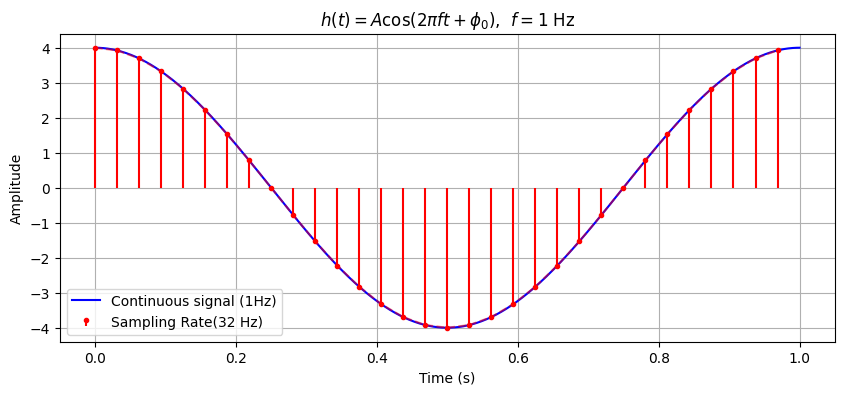

In [65]:
#@title Plot
plt.figure(figsize=(10, 4))
plt.plot(t_continuous, continuous_signal, label=f'Continuous signal ({FREQUENCY}Hz)', color='b')
plt.plot(t_discrete, discrete_signal, 'r--', alpha=0.5)
plt.stem(t_discrete, discrete_signal,label=f'Sampling Rate({SAMPLING_RATE} Hz)', basefmt=" ", linefmt='r', markerfmt='r.')

plt.title(rf'$h(t) = A \cos(2\pi f t + \phi_0)$,  $f = {FREQUENCY}$ Hz')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid()
plt.legend()
plt.show()

## ⭕ Quest: Dominio del Tiempo

1. **Efecto de la frecuencia de la señal ($f$):**
   * Ajusta `SAMPLING_RATE = 32 Hz`. ¿Qué ocurre con la gráfica discreta (puntos rojos) conforme incrementas `FREQUENCY` a $4\text{ Hz}$, $8\text{ Hz}$, $16\text{ Hz}$, $30\text{ Hz}$ y $33\text{ Hz}$?
   * ¿Por qué la señal muestreada de $30\text{ Hz}$ aparenta oscilar a una frecuencia mucho más baja ($2\text{ Hz}$)?.

2. **Límite de Nyquist y Colapso de Fase:**
   * Si mantienes `SAMPLING_RATE = 32 Hz` y fijas `FREQUENCY = 16 Hz` ($f_{cos} = f_{srate} / 2$), ¿qué forma adquieren los puntos muestreados?
   * ¿Qué pasaría si introducimos un desfase $\phi_0 = \pi/2$ (recordar: $cos(\phi_0) = \sin(\phi_0 + \pi /2 )$)?
   
   ¿Cuanto tendría que valer $\phi_0$ para que la señal comience en $-A = -4$?

3. **Reducción de la Tasa de Muestreo ($f_{srate}$):**
   * Deja `FREQUENCY = 4 Hz` y reduce `SAMPLING_RATE` paulatinamente ($64 \to 32 \to 16 \to 8 \to 4$). ¿En qué punto la reconstrucción discreta deja de representar fielmente a la onda continua original?
   
4. **Límite Continuo vs. Discreto:**
   * En la simulación usamos `np.linspace(..., 1000)` para simular el tiempo "continuo". En una computadora digital, ¿existe la señal verdaderamente continua o solo tenemos muestreos muy densos?

---
## Nyquist-Shannon
 Para procesar, almacenar o analizar una señal física (continua) en una computadora digital, es necesario convertirla en una secuencia de números discretos mediante el proceso de **muestreo**.

El **Teorema de Muestreo de Nyquist-Shannon** establece la condición mínima indispensable para que una señal continua $h(t)$ pueda ser **reconstruida de forma exacta y sin pérdida de información** a partir de sus muestras discretas $h[n]$.

> **Enunciado:**  
> Si una señal continua $h(t)$ no contiene componentes de frecuencia superiores o iguales a una frecuencia máxima $f_{\max}$ (es decir, está limitada en banda), la **frecuencia de muestreo** $f_srate$ debe ser estrictamente mayor al doble de dicha frecuencia máxima:
>
> $$f_s > 2 f_{\max}$$

* **Frecuencia de Nyquist ($f_{\text{Nyquist}}$):** Es el límite superior absoluto de frecuencia que un sistema de muestreo a $f_s$ puede representar correctamente sin distorsión:
  $$f_{\text{Nyquist}} = \frac{f_s}{2}$$

## Aliasing (Solapamiento Espectral)

El **Aliasing** (o traslape espectral) ocurre cuando la condición de Nyquist se viola, es decir, cuando se intenta muestrear una señal que contiene componentes de frecuencia superiores a la mitad de la tasa de muestreo ($f > f_s / 2$).

¿Qué sucede físicamente cuando $f > f_s / 2$?

Al muestrear en el tiempo a intervalos discretos $T_s = 1/f_s$, el espectro de la señal en frecuencia se **duplica e independiza en copias periódicas** separadas por múltiplos de $f_s$.

Si la frecuencia de la onda supera el límite de Nyquist, la componente de alta frecuencia se **"repliega" (folds back)** sobre el rango de frecuencias medibles $[0, f_s/2]$, adoptando la identidad visual y matemática de una frecuencia más baja no existente en la señal original (un "alias" o fantasma).

#### Ecuación de la Frecuencia Aparente (Alias)
La frecuencia percibida en el dominio discreto ($f_{\text{alias}}$) viene dada por la distancia a la réplica entera más cercana de la tasa de muestreo $f_s$:

$$f_{\text{alias}} = |f - k \cdot f_s| \quad \text{donde } k \in \mathbb{Z} \text{ elige el múltiplo que hace } 0 \le f_{\text{alias}} \le \frac{f_s}{2}$$

> **Ejemplo Práctico:**  
> Si usas $f_s = 32\text{ Hz}$ ($f_{\text{Nyquist}} = 16\text{ Hz}$) e introduces una onda de $f = 30\text{ Hz}$:
> $$f_{\text{alias}} = |30 - 1 \cdot 32| = |-2| = 2\text{ Hz}$$
> *La computadora interpretará las muestras como si vinieran de una onda pura de $2\text{ Hz}$.*
---

# Espectro de Potencia y Fases

## Superposición de Tonos (Suma de Sinusoides)

Vamos a construir una serie de tiempo artificial sumando las siguientes componentes:

* un coseno con frecuencia 2 Hz
* un coseno con frecuencia 3 Hz
* Ambas con $A_i(amplitud) = 2$

A continuación construimos esta señal:

In [106]:
#@title Sum_sines

####### Parameters
SAMPLING_RATE = 2**8                    # 256 samples per second
SAMPLING_PERIOD = 1 / SAMPLING_RATE     # seconds between samples
DURATION = 10.0                          # seconds to record

N_SAMPLES = int(SAMPLING_RATE * DURATION)          # samples in the window
time = np.arange(0, DURATION, SAMPLING_PERIOD)     # discrete time vector [0, DURATION)

####### Amplitudes & frequencies
A1 = 2.0
F1 = 2.0
A2 = 2.0
F2 = 3.0
PHI_1 = np.pi/2
PHI_2 = np.pi/4

####### Signals
signal_1 = A1 * np.cos(2 * np.pi * F1 * time + PHI_1)
signal_2 = A2 * np.cos(2 * np.pi * F2 * time + PHI_2)
signal = signal_1 + signal_2


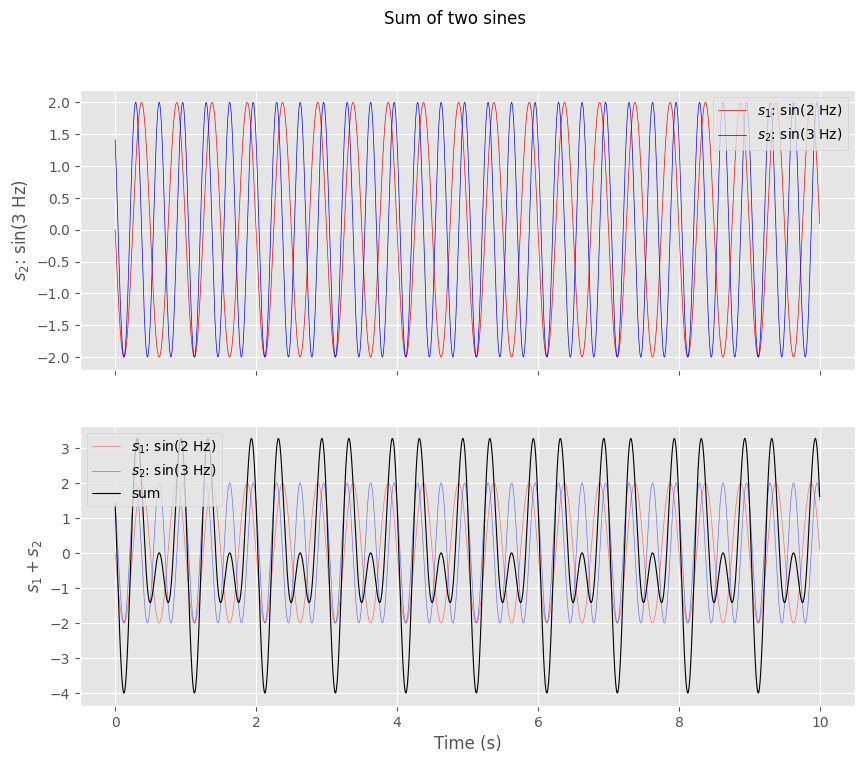

In [107]:
####### Plot
with plt.style.context('ggplot'):
  fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

  axes[0].plot(time, signal_1, color='r', linewidth=0.5,label=f'$s_1$: sin({F1:g} Hz)')
  axes[0].set_ylabel(f'$s_1$: sin({F1:g} Hz)')

  axes[0].plot(time, signal_2, color='b', linewidth=0.5,label=f'$s_2$: sin({F2:g} Hz)')
  axes[0].set_ylabel(f'$s_2$: sin({F2:g} Hz)')
  axes[0].legend(loc='upper right')


  axes[1].plot(time, signal_1, color='r', linewidth=0.5, alpha=0.5, label=f'$s_1$: sin({F1:g} Hz)')
  axes[1].plot(time, signal_2, color='b', linewidth=0.5, alpha=0.5, label=f'$s_2$: sin({F2:g} Hz)')
  axes[1].plot(time, signal, color='k', linewidth=0.8, label= 'sum')
  axes[1].set_ylabel('$s_1 + s_2$')
  axes[1].set_xlabel('Time (s)')
  axes[1].legend(loc = 'upper left')

  fig.suptitle('Sum of two sines')

  plt.show()

In [108]:
#@title Libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import fft, fftfreq

<>:43: SyntaxWarning: invalid escape sequence '\p'
<>:43: SyntaxWarning: invalid escape sequence '\p'
<>:43: SyntaxWarning: invalid escape sequence '\p'
<>:43: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_4747/892793120.py:43: SyntaxWarning: invalid escape sequence '\p'
  axes[1].annotate(f"{f:.1f} Hz\n  $\phi = {phi/np.pi:.2f}\pi$",xy=(f, phi),xytext=(f + 0.1, phi + 0.3),fontsize=9,fontweight="bold",color="darkred",arrowprops=dict(arrowstyle="->", color="crimson", lw=1))
/tmp/ipykernel_4747/892793120.py:43: SyntaxWarning: invalid escape sequence '\p'
  axes[1].annotate(f"{f:.1f} Hz\n  $\phi = {phi/np.pi:.2f}\pi$",xy=(f, phi),xytext=(f + 0.1, phi + 0.3),fontsize=9,fontweight="bold",color="darkred",arrowprops=dict(arrowstyle="->", color="crimson", lw=1))


signal: (2560,), spectrum: (2560,), one-sided: (1280,)


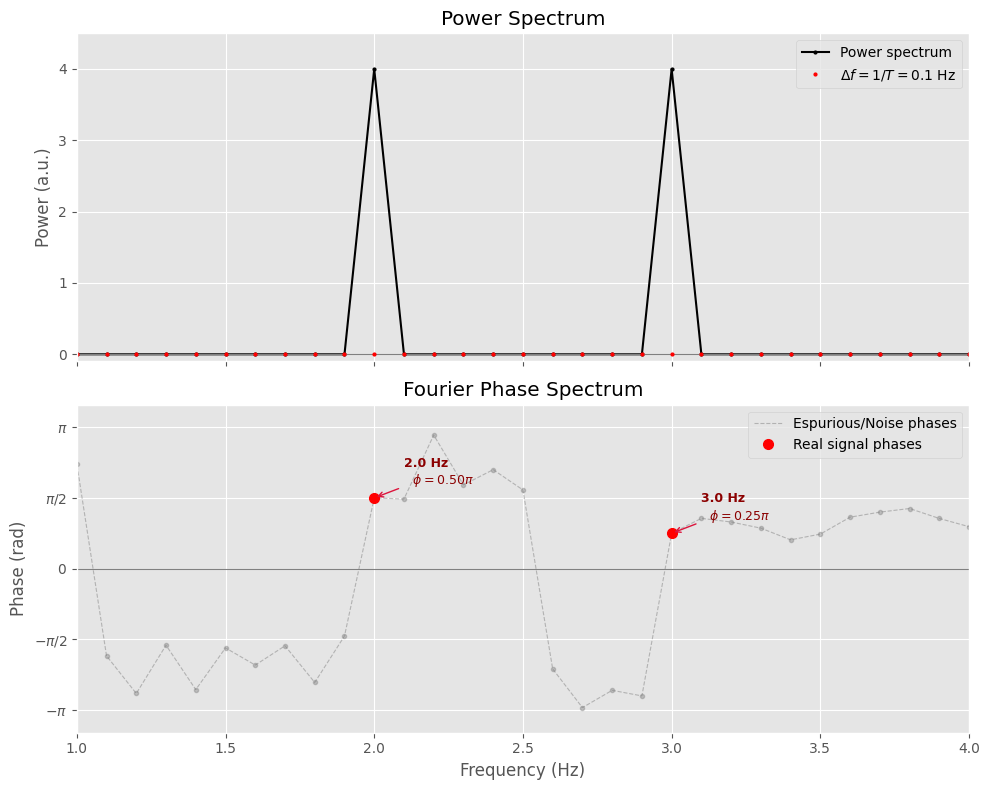

In [112]:
# @title Power & Phase Spectrum
spectrum = fft(signal)  # Coeficientes complejos
spectrum_onesided = spectrum[: N_SAMPLES // 2]
frequencies = fftfreq(N_SAMPLES, SAMPLING_PERIOD)[: N_SAMPLES // 2]

amplitude = 2 * np.abs(spectrum_onesided) / N_SAMPLES  # one-sided amplitude
power_spectrum = amplitude**2  # power ~ A²
fourier_phases = np.angle(spectrum_onesided)  # Fases reales calculadas (-pi a pi)

# 2. Identificacion de las frecuencias presentes (F1 y F2)
threshold = 0.1 * np.max(amplitude)  # Umbral para detectar las componentes principales
mask_peaks = amplitude > threshold   # Máscara para resaltar los bines con señal real

print(f"signal: {signal.shape}, spectrum: {spectrum.shape}, one-sided:"f" {amplitude.shape}")

# 3. Visualizacion con 2 Subplots
with plt.style.context("ggplot"):
  fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

  # ----------------------------------------------------
  # Subplot 1: Espectro de Potencia (PSD)
  # ----------------------------------------------------
  axes[0].plot(frequencies,power_spectrum,"k-",marker=".",markersize=4,label="Power spectrum")
  axes[0].axhline(0, color="gray", linewidth=0.8)
  bin_spacing = np.zeros_like(power_spectrum)
  axes[0].plot(frequencies,bin_spacing,"r.",markersize=4,label=rf"$\Delta f = 1/T = {1/DURATION:g}$ Hz")
  axes[0].set_title("Power Spectrum")
  axes[0].set_ylabel("Power (a.u.)")
  axes[0].set_ylim(-0.1, 4.5)
  axes[0].legend(loc="upper right")

  # -------------------------------------------
  # Subplot 2: Fase de Fourier vs. Frecuencia
  # -------------------------------------------
  axes[1].plot(frequencies,fourier_phases,color="gray",linestyle="--",alpha=0.5,linewidth=0.8,label="Espurious/Noise phases")
  axes[1].plot(frequencies,fourier_phases,"o",color="gray",alpha=0.4,markersize=3)

  #Resalta en ROJO únicamente las fases de los bines con energía real
  axes[1].plot(frequencies[mask_peaks],fourier_phases[mask_peaks],"ro",markersize=7,label="Real signal phases")

  # Anotación textual de la fase medida en los picos
  for f, phi in zip(frequencies[mask_peaks], fourier_phases[mask_peaks]):
    axes[1].annotate(f"{f:.1f} Hz\n  $\phi = {phi/np.pi:.2f}\pi$",xy=(f, phi),xytext=(f + 0.1, phi + 0.3),fontsize=9,fontweight="bold",color="darkred",arrowprops=dict(arrowstyle="->", color="crimson", lw=1))

  axes[1].axhline(0, color="gray", linewidth=0.8)
  axes[1].set_title("Fourier Phase Spectrum")
  axes[1].set_xlabel("Frequency (Hz)")
  axes[1].set_ylabel("Phase (rad)")
  axes[1].set_xlim(1, 4)
  axes[1].set_ylim(-np.pi - 0.5, np.pi + 0.5)

  # Eje Y con múltiplos legibles de pi
  axes[1].set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
  axes[1].set_yticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"])
  axes[1].legend(loc="upper right")
  plt.tight_layout()
  plt.show()

In [ ]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(phi[:N//2], amp[:N//2],'r*')
# ax.plot(phi[N//2:], amp[N//2:],'b*')
# plt.xlim(-30,650)
# ax.set_rmax(2)
ax.set_rticks([0.1, 0.5, 1])  # Less radial ticks
# ax.set_rlabel_position(-30.5)  # Move radial labels away from plotted line
ax.grid(True)
# ax.set_title("Analitical Phase for "+ B_lbs[i]+' band', va='bottom')

### ⭕ Dominio de la Frecuencia (PSD)

* Genera la misma gráfica pero con f2=2.9. ¿Qué sucede con la amplitud y la potencia?

* Si deseas distinguir los dos componentes frecuenciales cercanas ($2.0\text{ Hz}$ y $2.9\text{ Hz}$), ¿qué es más efectivo: aumentar la tasa de muestreo `SAMPLING_RATE` o aumentar la duración `DURATION` de la grabación? *(Pista: $\Delta f = 1 / T$)*.

* Graficar $\phi_i(f_i)$ vs. $f_i$ Nota: $\phi_i = \arctan(\frac{I_i}{R_i})$ corresponde a las fases de Fourier

* Graficar valores de FFT: $z_i = R_i + jI_i$ en el plano complejo

* Para una señal con frecuencia de registro de $2^8$, graficar la relación: $\Delta t(t_f - t_i)$ vs. $\Delta f(f_f-f_i)$, donde $\Delta t$ es el vector de tiempo y $\Delta f$ es el vector de la frecuencia.
  


Pista:

El bin $k$ de la FFT corresponde a la frecuencia:

$$f_k = \frac{k}{N \cdot \Delta t} = k \cdot \Delta f, \quad \Delta f = \frac{1}{T} = \frac{f_s}{N}$$

y los bins con $k > N/2$ son frecuencias negativas "plegadas" (equivale a $k - N$).


## AUDIO

In [3]:
!pip install -q symbulate
# from symbulate import
# from IPython.display import Audio

In [10]:
from IPython.display import Audio

srate = 3000 #44100    # Frecuencia de muestreo (1024 Hz)
duracion = 1  # Duración del audio en segundos

frecuencia_do = 261.63   # Do (C4)
frecuencia_mi = 329.63   # Mi (E4)
frecuencia_sol = 392.00  # Sol (G4)
t = np.linspace(0, duracion, int(srate * duracion))

sig_do = np.sin(2 * np.pi * frecuencia_do * t)
sig_mi = np.sin(2 * np.pi * frecuencia_mi * t)
sig_sol = np.sin(2 * np.pi * frecuencia_sol * t)
acorde_do_mayor = sig_do + sig_mi + sig_sol
acorde_do_mayor /= np.max(np.abs(acorde_do_mayor))
Audio(acorde_do_mayor, rate=srate)

In [8]:
sig_do = np.sin(2 * np.pi * frecuencia_do * t)
sig_mi = 20*np.sin(2 * np.pi * frecuencia_mi * t)
sig_sol = np.sin(2 * np.pi * frecuencia_sol * t)
acorde_do_mayor = sig_do + sig_mi + sig_sol
acorde_do_mayor /= np.max(np.abs(acorde_do_mayor))
Audio(acorde_do_mayor, rate=srate)

In [9]:
sig_do = np.sin(2 * np.pi * frecuencia_do * t)
sig_mi = np.sin(2 * np.pi * frecuencia_mi * t)
sig_sol = 20*np.sin(2 * np.pi * frecuencia_sol * t)
acorde_do_mayor = sig_do + sig_mi + sig_sol
acorde_do_mayor /= np.max(np.abs(acorde_do_mayor))
Audio(acorde_do_mayor, rate=srate)

⭕ Sonido

* Graficar espectro de potencias

* Graficar $\phi_i(f_i)$ vs. $f_i$ Nota: $\phi_i = \arctan(\frac{I_i}{R_i})$ corresponde a las fases de Fourier

* Graficar valores de FFT: $z_i = R_i + jI_i$ en el plano complejo


In [ ]:
#inserte codigo

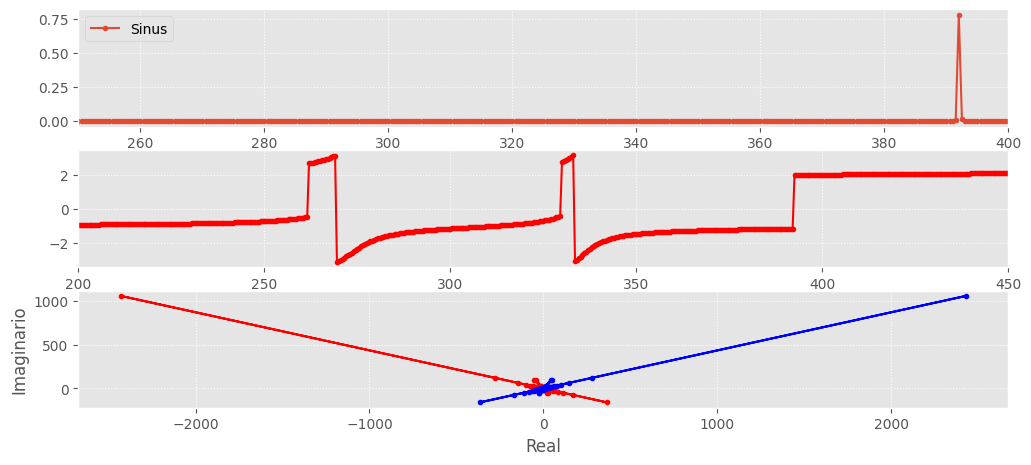

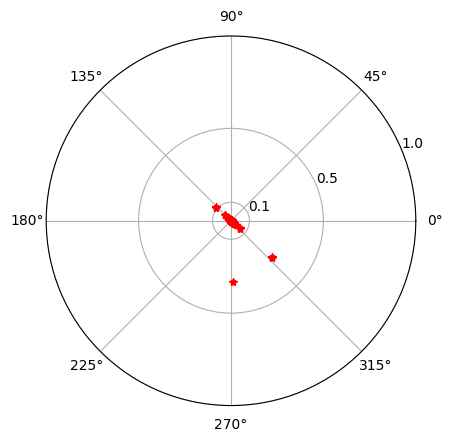